# 06 · Zeros of g: absorption, blow-up, non-uniqueness and the selected solution

At a zero $z$ of $g$ the speed $\sigma\kappa$ of a front tends to zero,
but $\dot\sigma = \alpha\kappa/2$ stays constant. So fronts reach the zero
**in finite time** and are absorbed into a stationary interface. The
Lax-type interface condition of *Failure of uniqueness* becomes a sign
condition on θ, the same for either sign of $g$:

$$\theta(z^-)\ \ge\ 0\ \ \ge\ \theta(z^+),$$

so characteristics enter the zero and never leave it. Here $f = xu^2$
throughout (`g = x`, represented exactly by $g_\Delta$).

In [1]:
# Use the local checkout if present; otherwise install from GitHub (needs the repository to be public).
import sys, subprocess, importlib.util
from pathlib import Path
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/hetfront/__init__.py").is_file()), None)
if local_src is not None:
    sys.path.insert(0, str(local_src))
elif importlib.util.find_spec("hetfront") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/parasuramv/heterogeneous-front-tracking"])
import numpy as np
import matplotlib.pyplot as plt
import hetfront
from hetfront import (HeteroFrontTracker, PeriodicHeteroFrontTracker, MultiplicativeFlux,
                      PiecewiseAffine, trajectory)
from hetfront.visualization import (observe_tracker, plot_spacetime, plot_profile,
                                    plot_heterogeneity, plot_diagnostics, plot_circle, overview)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
print("hetfront", hetfront.__version__, "from", "local checkout" if local_src else "installed package")

hetfront 0.1.0 from local checkout


In [2]:
gx = PiecewiseAffine([-1, 1], [-1, 1], extend="affine")   # g_Δ = x exactly
def xu2(delta):
    return MultiplicativeFlux(gx, delta)

## The shock $y(t) = -(t-2)^2/4$

Take the bounded datum $u_0 = -1/\sqrt{-x}$ for $x<-1$ and $u_0 = 0$
otherwise. In levels this is $\theta = 1 \mid 0$ at $x=-1$, a single shock
with $\kappa = 1$. The closed form reproduces the manuscript's curve to
machine precision, and the front is absorbed at $t = 2$.

In [3]:
tr = HeteroFrontTracker.from_theta(xu2(0.01), [-1.0], [1.0, 0.0])
for t in (0.5, 1.0, 1.5, 1.99):
    tr.run(t)
    print(f"t = {t:4}: front at {tr.fronts[0].x(t):+.15f}, -(t-2)^2/4 = {-(t-2)**2/4:+.15f}")
tr.run(3.0)
print("after t = 2:", tr.counts["absorption"], "absorption; interface", tr.interfaces[0])

t =  0.5: front at -0.562500000000000, -(t-2)^2/4 = -0.562500000000000
t =  1.0: front at -0.250000000000000, -(t-2)^2/4 = -0.250000000000000
t =  1.5: front at -0.062500000000000, -(t-2)^2/4 = -0.062500000000000
t = 1.99: front at -0.000025000000000, -(t-2)^2/4 = -0.000025000000000
after t = 2: 1 absorption; interface Interface(x=0.0, kL=100, kR=0, left_sign=-1.0, right_sign=1.0, left_cell=1, right_cell=2, last_time=2.0, absorbed=0.0)


## Blow-up from bounded data

For $u_0 = -1$ on $|x|\le1$, characteristics are $q_0(1-t)^2$ and carry
$u = -1/(1-t)$, so $\|u\|_\infty$ blows up at $t = 1$. The flux level stays
bounded, $|\theta|\le1$, which is what makes front tracking possible.

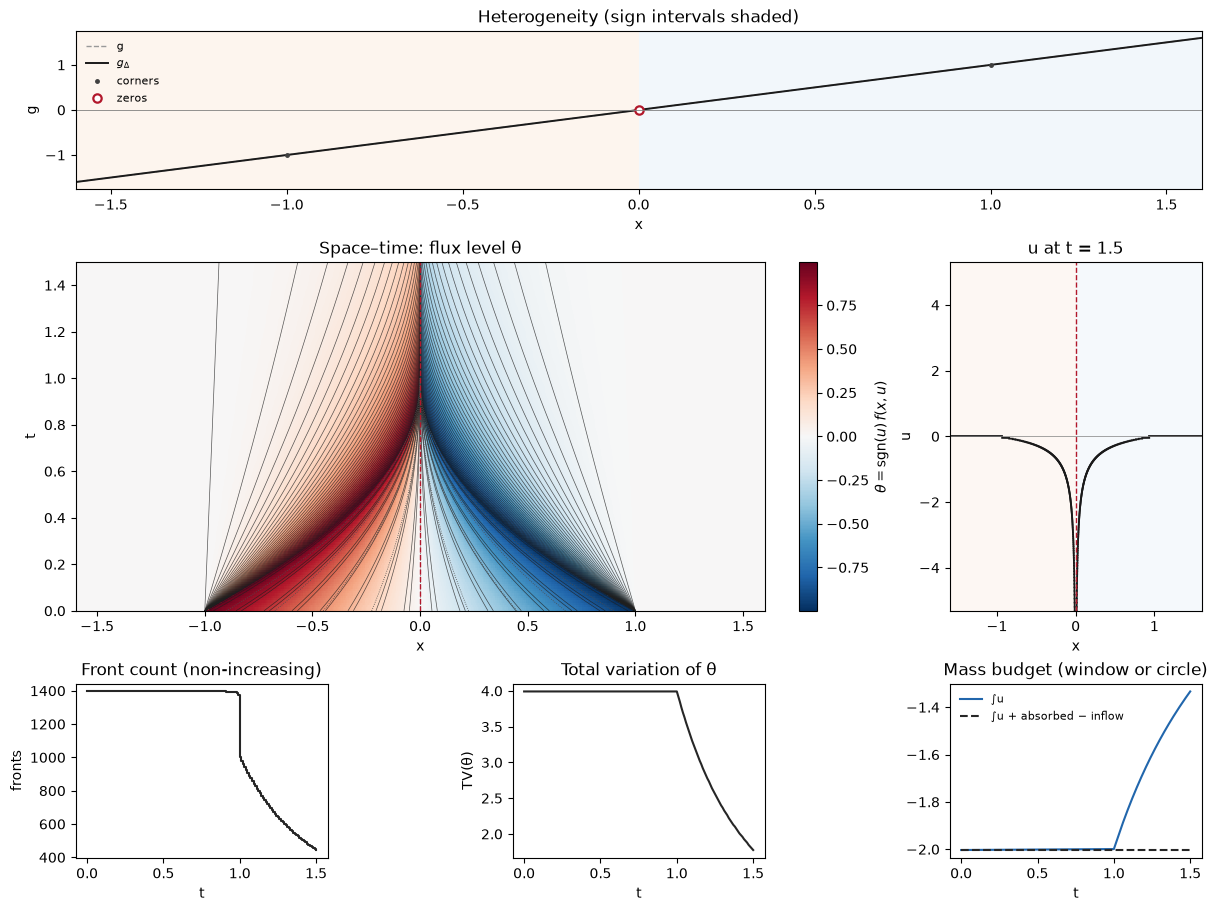

  t     u(0.1(1-t)^2, t)   exact -1/(1-t)
0.05          -1.0421      -1.0526
0.15          -1.1646      -1.1765
0.25          -1.3199      -1.3333
0.35          -1.5230      -1.5385
0.45          -1.7999      -1.8182
0.55          -2.1999      -2.2222
0.65          -2.8284      -2.8571
0.75          -3.9598      -4.0000
0.85          -6.5997      -6.6667
0.95         -19.7990     -20.0000


In [4]:
flux = xu2(0.002)
u0 = lambda x: np.where(np.abs(x) <= 1, -1.0, 0.0)
tr = HeteroFrontTracker.from_function(flux, u0, (-1.5, 1.5), cells=600)
h = observe_tracker(tr, np.linspace(-1.6, 1.6, 801), np.linspace(0, 1.5, 151))
chars = [flux.characteristic(q, float(flux.theta_of(np.array([q]), np.array([-1.0]))[0]), 1.5)
         for q in np.linspace(-0.9, 0.9, 9)]
overview(h, exact_g=lambda x: x, characteristics=chars)
plt.show()
ts = np.linspace(0.05, 0.95, 10)
probe = HeteroFrontTracker.from_function(flux, u0, (-1.5, 1.5), cells=600)
print("  t     u(0.1(1-t)^2, t)   exact -1/(1-t)")
for t in ts:
    probe.run(t)
    print(f"{t:4.2f}   {probe.sample_u(0.1 * (1 - t)**2):14.4f}   {-1/(1-t):10.4f}")

## Non-uniqueness and the selected solution

Data $u_0 = -1/\sqrt{-x}$ for $x<0$ and $0$ for $x>0$ (θ = 1 | 0, which is
admissible) define a stationary entropy solution. They also admit infinitely
many other entropy solutions $u_\lambda$. Each emits $1/\sqrt{x}$ from the
zero at time λ behind a shock $\gamma(t-\lambda) = (t-\lambda)^2/4$.

Front tracking selects the stationary one, because $\theta(0^+) > 0$ violates
the interface condition. Setting `enforce_interface=False` lets us build the
others approximately: at time λ we seed θ = 1 on $(0,\varepsilon)$.
The seeded shock is $(\sqrt{\varepsilon}+(t-\lambda)/2)^2$,
not exactly $(t-\lambda)^2/4$; its seed has mass $2\sqrt{\varepsilon}$.
Thus the initial datum is perturbed, and the target family is recovered
as the seed tends to zero. Disabling selection does not enforce entropy
for arbitrary data: the zero-interface entropy inequality is
$\theta(z^+)\le\theta(z^-)$. These balanced traces satisfy it.

Here “entropy solution” uses the manuscript's unbounded, locally
integrable class satisfying the Kružkov inequalities without separately
requiring the weak conservation law. This is broader than the standard
bounded entropy-solution class.

λ = 0.0: entropy solution, interface admissible? False; L1 distance to the selected solution on [0, 3] at t = 3.0: 3.002
λ = 0.75: entropy solution, interface admissible? False; L1 distance to the selected solution on [0, 3] at t = 3.0: 2.252
λ = 1.5: entropy solution, interface admissible? False; L1 distance to the selected solution on [0, 3] at t = 3.0: 1.502


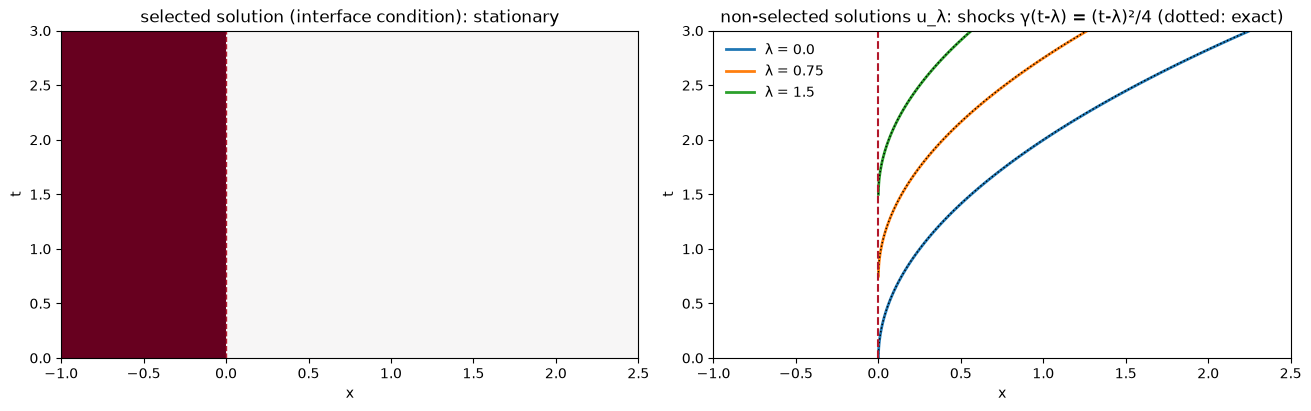

In [5]:
delta, eps, T = 0.01, 1e-6, 3.0
selected = HeteroFrontTracker.from_theta(xu2(delta), [0.0], [1.0, 0.0])
x = np.linspace(-1, 2.5, 701)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
hs = observe_tracker(selected, x, np.linspace(0, T, 61))
plot_spacetime(hs, ax=axes[0], colorbar=False)
axes[0].set_title("selected solution (interface condition): stationary")
for lam in (0.0, 0.75, 1.5):
    other = HeteroFrontTracker.from_theta(xu2(delta), [0.0, eps], [1.0, 1.0, 0.0], enforce_interface=False)
    other.run(T - lam)
    front = other.fronts[0]
    ts = np.linspace(0, T - lam, 100)
    axes[1].plot([front.x(t) for t in ts], ts + lam, lw=2, label=f"λ = {lam}")
    axes[1].plot((ts)**2 / 4, ts + lam, "k:", lw=1)
    print(f"λ = {lam}: entropy solution, interface admissible? {other.interface_admissible()}; "
          f"L1 distance to the selected solution on [0, 3] at t = {T}: "
          f"{abs(other.integral(0, 3) - selected.integral(0, 3)):.3f}")
axes[1].set(xlim=(-1, 2.5), ylim=(0, T), xlabel="x", ylabel="t",
            title="non-selected solutions u_λ: shocks γ(t-λ) = (t-λ)²/4 (dotted: exact)")
axes[1].axvline(0, color="#b2182b", ls="--")
axes[1].legend(frameon=False)
plt.show()

## Mass and the interface

Entropy solutions here need not be weak solutions: mass can disappear into
a zero, or emerge from it. Each interface accumulates the net flux
$f(z^-) - f(z^+)$, and $\int u + \text{absorbed}$ is conserved to roundoff.

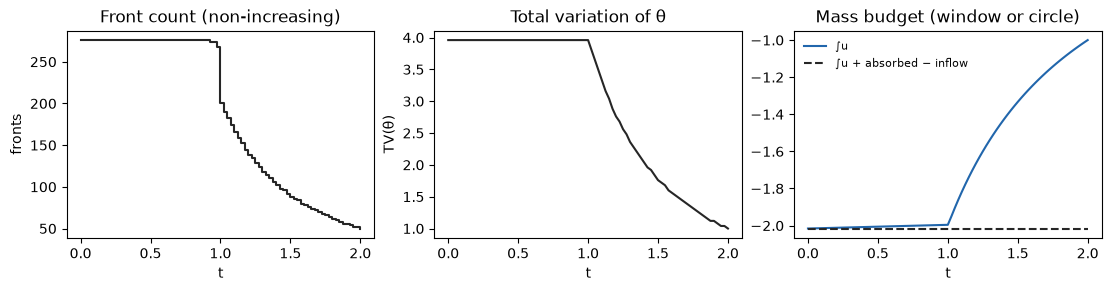

max |∫u + absorbed − inflow − initial| = 5.861977570020827e-14


In [6]:
tr = HeteroFrontTracker.from_function(xu2(0.01), u0, (-1.5, 1.5), cells=120)
h = observe_tracker(tr, np.linspace(-3, 3, 401), np.linspace(0, 2, 81))
plot_diagnostics(h)
plt.show()
d = h.diagnostics
print("max |∫u + absorbed − inflow − initial| =", np.max(np.abs(d["mass"] + d["absorbed"] - d["inflow"] - d["mass"][0])))

## Interface layer versus emission

The manuscript sets $\theta^\delta = 0$ on an ε-neighbourhood of each
zero. With ε = 0 the code instead emits a δ-fan from the zero whenever the
data are inadmissible next to it. The following experiment compares
their small-layer behaviour; it is not a general convergence proof. The data are
$\theta = 0.5$ on both sides, which is inadmissible on the right.

In [7]:
delta, T = 0.01, 1.0
x = np.linspace(-1, 1, 2001)
base = HeteroFrontTracker.from_theta(xu2(delta), [], [0.5], interface_layer=0.0).run(T)
print("emission at t = 0:", base.counts["initial_emission"])
for eps in (0.2, 0.05, 0.0125, 0.003):
    tr = HeteroFrontTracker.from_theta(xu2(delta), [], [0.5], interface_layer=eps).run(T)
    print(f"ε = {eps:6.4f}: ∫|θ_ε − θ_0| over [-1, 1] = {tr.theta_l1_distance(base, -1, 1):.4f}")

emission at t = 0: 1
ε = 0.2000: ∫|θ_ε − θ_0| over [-1, 1] = 0.2822
ε = 0.0500: ∫|θ_ε − θ_0| over [-1, 1] = 0.1303
ε = 0.0125: ∫|θ_ε − θ_0| over [-1, 1] = 0.0589
ε = 0.0030: ∫|θ_ε − θ_0| over [-1, 1] = 0.0273
